# **MÓDULO 20 - Projeto de Credit Score - Naive Bayes**


No módulo 17 vocês realizaram a primeira etapa do projeto de crédito de vocês.
Então fizeram o tratamendo dos dados, balancearam as classes, transformaram as variáveis categóricas e separam base de treino e teste.
Nessa aula aplicaremos o algoritmo de naive bayes a base de vocês afim de tentarmos trazer previsões do score de crédito.

**IMPORTANTE:** Não se esqueçam de ao enviar o código de vocês para os tutores, enviarem as bases, pois como cada um de vocês realizou as alterações de tratamento indidualmente o tutor precisa ter acesso aos seus dados individuais.

In [5]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix
from sklearn.naive_bayes import GaussianNB
from sklearn.metrics import accuracy_score
from sklearn.metrics import recall_score

Durante a aula nossa variável a ser prevista (churn) continha apenas 2 categorias, a base de vocês contém mais. O Naive Bayes pode ser aplicado para problemas de classificação com múltiplas classes da mesma forma que para problemas de classificação binária. O Naive Bayes é um algoritmo de classificação probabilístico que calcula a probabilidade de uma amostra pertencer a cada classe e seleciona a classe com a maior probabilidade como a previsão final.
Em resumo, o Naive Bayes pode ser aplicado da mesma maneira para problemas de classificação com múltiplas classes, e os mesmos princípios se aplicam em termos de treinamento, avaliação e aplicação do modelo.

# 1) Comece carregando as bases de treino (X e y) e teste (X e y).
Verifique se o número de linhas condiz, se as variáveis estão corretas sendo apenas a de score para y e as demais nas bases de X e por último, se Y está balanceada no teste.

In [16]:
x_test = pd.read_csv("base_teste_X.csv", delimiter=',')
y_test = pd.read_csv("base_teste_y.csv", delimiter=',')
x_treino = pd.read_csv("base_treino_X.csv", delimiter=',')
y_treino = pd.read_csv("base_treino_y.csv", delimiter=',')

In [19]:
# Quantidade de linhas e colunas de cada base
print("X treino:", x_treino.shape)
print("y treino:", y_treino.shape)
print("X teste :", x_test.shape)
print("y teste :", y_test.shape)

X treino: (210, 10)
y treino: (210, 1)
X teste : (26, 10)
y teste : (26, 1)


In [20]:
# Quantidade absoluta de cada classe
print("Treino:")
print(y_treino.value_counts())

print("\nTeste:")
print(y_test.value_counts())

# Proporção em porcentagem
print("\nProporção treino:")
print(y_treino.value_counts(normalize=True) * 100)

print("\nProporção teste:")
print(y_test.value_counts(normalize=True) * 100)

Treino:
Credit Score
1               70
2               70
0               70
Name: count, dtype: int64

Teste:
Credit Score
2               18
1                6
0                2
Name: count, dtype: int64

Proporção treino:
Credit Score
1               33.333333
2               33.333333
0               33.333333
Name: proportion, dtype: float64

Proporção teste:
Credit Score
2               69.230769
1               23.076923
0                7.692308
Name: proportion, dtype: float64


# 2) Aplique o algoritmo de Naive Bayes aos dados de treinamento.

In [21]:
credito_nb = GaussianNB()

In [22]:
credito_nb.fit(x_treino,y_treino)

D:\projetos ebac\.venv\Lib\site-packages\sklearn\utils\validation.py:1368: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](3,)","[70.,70.,70.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](3,)","[0.33,0.33,0.33]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](3,)","[0,1,2]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1.018
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](10,)","['Age','Gender','Income',...,'Education_Doctorate', 'Education_High School Diploma',""Education_Master's Degree""]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,10
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](3, 10)","[[ 28.01, 0. ,32284.36,..., 0. , 0.34, 0. ], [ 28.87, 0.34,55809.58,..., 0.01, 0.1 , 0. ], [ 41.7 , 0.5 ,99421.43,..., 0.24, 0.1 , 0.36]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](3, 10)","[[1.53e+00,1.02e+00,1.45e+07,...,1.02e+00,1.24e+00,1.02e+00], [1.04e+01,1.24e+00,5.20e+07,...,1.03e+00,1.11e+00,1.02e+00], [4.61e+01,1.27e+00,6.68e+08,...,1.20e+00,1.11e+00,1.25e+00]]"


# 3) Faça a avaliação do modelo com os dados de treinamento.
Traga a acurácia, recall e plote a matriz de confusão. Não se esqueça de avaliar com suas palavras o desempenho do modelo, interpretando as métricas.

Dica: Para calcularmos o recall em classificação multi classe precisamos usar o atributo macro:
recall = recall_score(y_train, y_pred_train, average='macro')

Analisando os resultados obtidos, o modelo Naive Bayes apresentou uma acurácia e um recall macro de aproximadamente 99,05% na base de treino. Esse valor é muito alto e indica que o modelo conseguiu classificar corretamente quase todos os exemplos utilizados durante o treinamento.

No entanto, como as métricas foram calculadas na própria base de treino, existe a possibilidade de o modelo estar memorizando os dados, o que caracteriza um possível overfitting. Por isso, é necessário avaliar o desempenho também na base de teste, que contém dados não utilizados no treinamento. Assim, será possível verificar se o modelo realmente generaliza bem para novos exemplos ou se o resultado alto ocorreu apenas porque ele já conhecia os dados de treino.

In [23]:
y_previsao= credito_nb.predict(x_treino)

In [25]:
accuracy = accuracy_score(y_treino, y_previsao)
print(accuracy)

0.9904761904761905


In [37]:
recall = recall_score(y_treino, y_previsao, average='macro')
print(recall)


0.9904761904761905


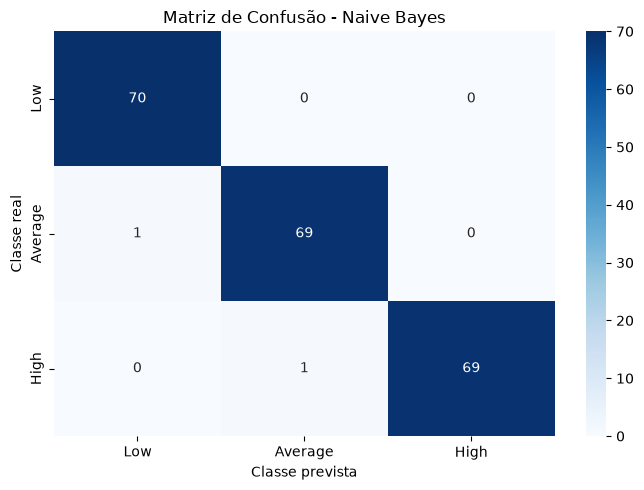

In [30]:
conf_matrix = confusion_matrix(y_treino, y_previsao)

plt.figure(figsize=(7, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=["Low", "Average", "High"],
    yticklabels=["Low", "Average", "High"]
)

plt.title("Matriz de Confusão - Naive Bayes")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()


# 4) Aplique o modelo aos dados de teste e realize a avaliação dos resultados, da mesma forma que fez acima. Não se esqueça de avaliar com as suas palavras e comparar o desempenho da base treino com a teste.

O modelo Naive Bayes apresentou acurácia e recall macro de aproximadamente 95% na base de treino e 100% na base de teste. Esse resultado mostra que o modelo conseguiu classificar corretamente todos os exemplos da base de teste, mesmo sem tê-los utilizado durante o treinamento.

Como o desempenho no teste foi igual ou superior ao desempenho no treino, não há indícios de overfitting. Isso sugere que o modelo foi capaz de generalizar bem para dados novos. O bom resultado pode estar relacionado às variáveis Income e Home Ownership, que apresentaram forte correlação com o Credit Score e ajudaram na separação das classes.

In [38]:
y_previ= credito_nb.predict(x_test)

In [39]:
accuracyy = accuracy_score(y_test, y_previ)
print(accuracyy)

1.0


In [40]:
recalll = recall_score(y_test, y_previ, average='macro')
print(recalll)

1.0


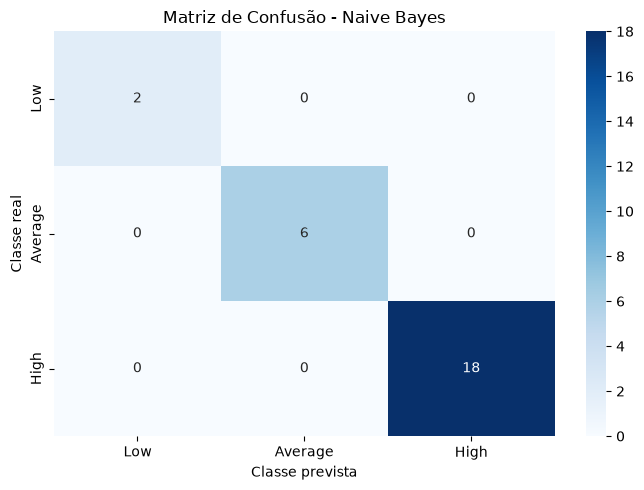

In [41]:
conf_matrix = confusion_matrix(y_test, y_previ)

plt.figure(figsize=(7, 5))
sns.heatmap(
    conf_matrix,
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=True,
    xticklabels=["Low", "Average", "High"],
    yticklabels=["Low", "Average", "High"]
)

plt.title("Matriz de Confusão - Naive Bayes")
plt.xlabel("Classe prevista")
plt.ylabel("Classe real")
plt.tight_layout()
plt.show()

In [43]:
# conferiddo alguma coisas
print(x_treino.columns)
print(y_treino.columns)
print(x_test.columns)
print(y_test.columns)

Index(['Age', 'Gender', 'Income', 'Marital Status', 'Number of Children',
       'Home Ownership', 'Education_Bachelor's Degree', 'Education_Doctorate',
       'Education_High School Diploma', 'Education_Master's Degree'],
      dtype='str')
Index(['Credit Score'], dtype='str')
Index(['Age', 'Gender', 'Income', 'Marital Status', 'Number of Children',
       'Home Ownership', 'Education_Bachelor's Degree', 'Education_Doctorate',
       'Education_High School Diploma', 'Education_Master's Degree'],
      dtype='str')
Index(['Credit Score'], dtype='str')


In [44]:
# Ver correlação das variáveis numéricas com o alvo
correlacoes = x_treino.copy()
correlacoes["alvo"] = y_treino.values.ravel()
print(correlacoes.corr(numeric_only=True)["alvo"].sort_values(ascending=False))

alvo                             1.000000
Income                           0.858837
Home Ownership                   0.831929
Age                              0.737027
Marital Status                   0.684744
Number of Children               0.540648
Gender                           0.454150
Education_Master's Degree        0.450225
Education_Doctorate              0.354167
Education_Bachelor's Degree      0.263889
Education_High School Diploma   -0.257536
Name: alvo, dtype: float64


# 5) Descreva com suas palavras o projeto desenvolvido nessa atividade e qual o nosso objetivo principal ao aplicarmos o algoritmo de naive bayes a base de crédito.
Utilize pelo menos 4 linhas.

Dica: Caso você ainda esteja tendo dificuldade em visualizar a aplicação dos projetos e objetivo, consulte seus tutores!

Neste projeto, foi desenvolvido um modelo de classificação utilizando o algoritmo Naive Bayes para prever o Credit Score dos clientes. A base continha informações como idade, renda, estado civil, número de filhos, gênero, situação de moradia e escolaridade, que foram utilizadas como variáveis explicativas.

O objetivo principal foi classificar cada cliente em uma das três categorias de score de crédito: Low, Average ou High. Para isso, os dados foram preparados, divididos em treino e teste, e o modelo foi treinado e avaliado com métricas como acurácia, recall e matriz de confusão, permitindo verificar sua capacidade de prever corretamente o score de novos clientes.